# 1. Загрузка данных и библиотек

На этом этапе подключаются необходимые библиотеки и загружается подготовленный датасет.

Для анализа используются:
- pandas для работы с таблицами;
- NumPy для вычислений;
- Matplotlib и Seaborn для визуализации;
- scikit-learn для построения и оценки логистической регрессии.

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

from main_project.config import (
    DATA_PROCESSED,
    FIGURES,
    TARGET,
    RANDOM_STATE,
    TEST_SIZE,
)

sns.set_theme(style="whitegrid", palette="deep")

FIGURES.mkdir(parents=True, exist_ok=True)

DATA_FULL = DATA_PROCESSED / "telco_encoded_full.csv"

df = pd.read_csv(DATA_FULL)

print(f"Файл: {DATA_FULL.name}")
print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
print(f"Целевая переменная: {TARGET}")

display(df.head())

Файл: telco_encoded_full.csv
Количество строк: 7043
Количество столбцов: 25
Целевая переменная: Churn Value


,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Monthly Charges,Total Charges,Churn Value,Internet Service_Fiber optic,Internet Service_No,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,33.964,-118.273,1,0,0,0,2,1,0,1,1,0,0,0,0,0,1,53.850,108.150,1,0,0,0,0,1
1,34.059,-118.307,0,0,0,1,2,1,0,0,0,0,0,0,0,0,1,70.700,151.650,1,1,0,0,1,0
2,34.048,-118.294,0,0,0,1,8,1,1,0,0,1,0,1,1,0,1,99.650,820.500,1,1,0,0,1,0
3,34.062,-118.316,0,0,1,1,28,1,1,0,0,1,1,1,1,0,1,104.800,3046.050,1,1,0,0,1,0
4,34.039,-118.266,1,0,0,1,49,1,1,0,1,1,0,1,1,0,1,103.700,5036.300,1,1,0,0,0,0


# 2. Первичная проверка данных

Проверяем размер таблицы, типы данных, пропуски и повторяющиеся строки.

Это позволяет понять, насколько данные готовы к дальнейшему анализу. Наличие числовых типов само по себе не гарантирует корректность данных: важно также понимать смысл каждого признака.

In [85]:
print("Информация о датасете:")
df.info()

print("\nПервые строки:")
display(df.head())

print("\nКоличество пропусков:")

missing_values = (
    df.isna()
    .sum()
    .to_frame(name="Количество пропусков")
)

display(missing_values[missing_values["Количество пропусков"] > 0])

print(f"\nКоличество полных дубликатов: {df.duplicated().sum()}")
print(f"Количество числовых столбцов: {df.select_dtypes(include=np.number).shape[1]}")
print(f"Количество нечисловых столбцов: {df.select_dtypes(exclude=np.number).shape[1]}")

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 25 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Latitude                                7043 non-null   float64
 1   Longitude                               7043 non-null   float64
 2   Gender                                  7043 non-null   int64  
 3   Senior Citizen                          7043 non-null   int64  
 4   Partner                                 7043 non-null   int64  
 5   Dependents                              7043 non-null   int64  
 6   Tenure Months                           7043 non-null   int64  
 7   Phone Service                           7043 non-null   int64  
 8   Multiple Lines                          7043 non-null   int64  
 9   Online Security                         7043 non-null   int64  
 10  Online Backup                        

,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Monthly Charges,Total Charges,Churn Value,Internet Service_Fiber optic,Internet Service_No,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,33.964,-118.273,1,0,0,0,2,1,0,1,1,0,0,0,0,0,1,53.850,108.150,1,0,0,0,0,1
1,34.059,-118.307,0,0,0,1,2,1,0,0,0,0,0,0,0,0,1,70.700,151.650,1,1,0,0,1,0
2,34.048,-118.294,0,0,0,1,8,1,1,0,0,1,0,1,1,0,1,99.650,820.500,1,1,0,0,1,0
3,34.062,-118.316,0,0,1,1,28,1,1,0,0,1,1,1,1,0,1,104.800,3046.050,1,1,0,0,1,0
4,34.039,-118.266,1,0,0,1,49,1,1,0,1,1,0,1,1,0,1,103.700,5036.300,1,1,0,0,0,0



Количество пропусков:


,Количество пропусков



Количество полных дубликатов: 0
Количество числовых столбцов: 25
Количество нечисловых столбцов: 0


В датасете 7043 наблюдения и 25 столбцов. До построения модели необходимо убедиться в отсутствии пропусков и повторяющихся записей. Даже если пропуски и дубликаты не обнаружены, это не исключает ошибок в значениях или кодировании признаков.

# 3. Сводный отчёт о качестве данных

Собираем основные характеристики датасета в одну таблицу. Такой отчёт помогает быстро оценить объём данных, пропуски, дубликаты и количество признаков.

In [86]:
quality_report = pd.DataFrame(
    {
        "Показатель": [
            "Количество наблюдений",
            "Количество столбцов",
            "Количество пропусков",
            "Количество полных дубликатов",
            "Количество числовых столбцов",
            "Количество нечисловых столбцов",
        ],
        "Значение": [
            len(df),
            df.shape[1],
            int(df.isna().sum().sum()),
            int(df.duplicated().sum()),
            df.select_dtypes(include=np.number).shape[1],
            df.select_dtypes(exclude=np.number).shape[1],
        ],
    }
)

display(quality_report)

,Показатель,Значение
0,Количество наблюдений,7043
1,Количество столбцов,25
2,Количество пропусков,0
3,Количество полных дубликатов,0
4,Количество числовых столбцов,25
5,Количество нечисловых столбцов,0


Сводный отчёт показывает общее техническое состояние данных. Результаты нужно интерпретировать вместе с предметным смыслом признаков: отсутствие пропусков не означает, что все значения корректны.

# 4. Статистическое описание признаков

Рассматриваем основные статистические характеристики числовых столбцов: среднее значение, стандартное отклонение, минимум, максимум и квартили.

Для бинарных признаков среднее значение можно интерпретировать как долю наблюдений со значением 1. Для кодированных категорий среднее может не иметь самостоятельного практического смысла.

In [87]:
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Latitude,7043.000,36.282,2.456,32.556,34.031,36.392,38.225,41.962
Longitude,7043.000,-119.799,2.158,-124.301,-121.815,-119.731,-118.043,-114.193
Gender,7043.000,0.505,0.500,0.000,0.000,1.000,1.000,1.000
Senior Citizen,7043.000,0.162,0.369,0.000,0.000,0.000,0.000,1.000
Partner,7043.000,0.483,0.500,0.000,0.000,0.000,1.000,1.000
Dependents,7043.000,0.231,0.422,0.000,0.000,0.000,0.000,1.000
Tenure Months,7043.000,32.371,24.559,0.000,9.000,29.000,55.000,72.000
Phone Service,7043.000,0.903,0.296,0.000,1.000,1.000,1.000,1.000
Multiple Lines,7043.000,0.422,0.494,0.000,0.000,0.000,1.000,1.000
Online Security,7043.000,0.287,0.452,0.000,0.000,0.000,1.000,1.000


Таблица позволяет увидеть диапазоны значений и различия в масштабах признаков. Например, стаж клиента и ежемесячные расходы измеряются в разных единицах, поэтому масштабирование может быть полезно при обучении логистической регрессии.

# 5. Анализ целевой переменной Churn Value

Целевая переменная показывает, ушёл ли клиент от компании:
- 0 означает, что клиент остался;
- 1 означает, что клиент ушёл.

Сначала изучим количество объектов каждого класса, а затем их доли. Это важно, потому что неравномерное распределение классов влияет на оценку качества модели.

,Количество,"Доля, %"
Churn Value,,
0,5174,73.460
1,1869,26.540


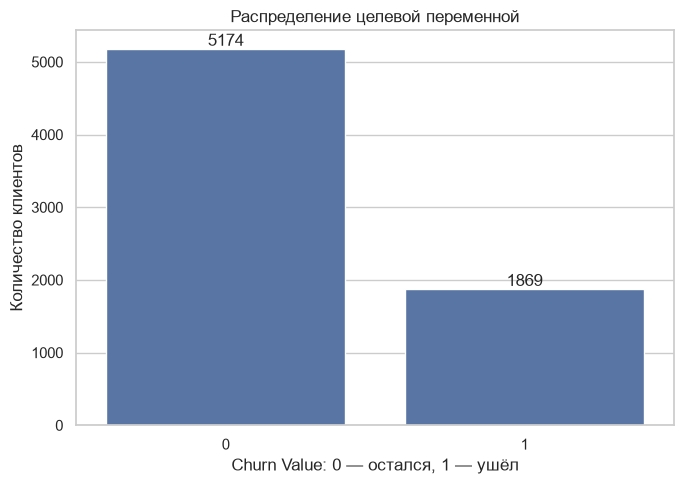

In [88]:
target_counts = df[TARGET].value_counts().sort_index()
target_percent = df[TARGET].value_counts(normalize=True).sort_index() * 100

target_report = pd.DataFrame(
    {
        "Количество": target_counts,
        "Доля, %": target_percent.round(2),
    }
)

target_report.index.name = TARGET
display(target_report)

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x=TARGET,
    order=[0, 1],
)

ax.set_title("Распределение целевой переменной")
ax.set_xlabel("Churn Value: 0 — остался, 1 — ушёл")
ax.set_ylabel("Количество клиентов")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(FIGURES / "01_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

В датасете 5174 клиента остались с компанией (73,46%), а 1869 клиентов ушли (26,54%). Классы распределены неравномерно. Поэтому одной Accuracy недостаточно для полноценной оценки модели: важно также учитывать Recall, Precision, F1 и ROC-AUC.

# 6. Анализ распределения числовых признаков

Изучаем распределения трёх основных количественных признаков:
- Tenure Months: срок обслуживания клиента в месяцах;
- Monthly Charges: ежемесячные расходы;
- Total Charges: общая сумма начислений.

Гистограммы помогают увидеть концентрацию значений, асимметрию распределений и возможные необычные наблюдения. Отдельно сравним распределения ушедших и оставшихся клиентов.

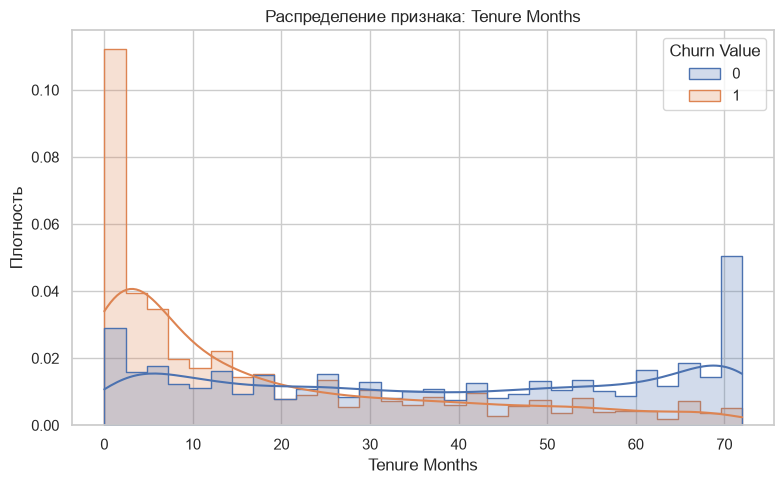

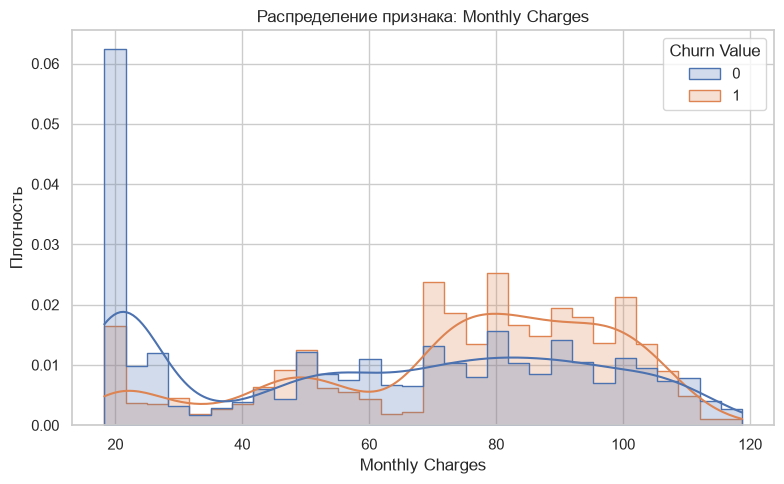

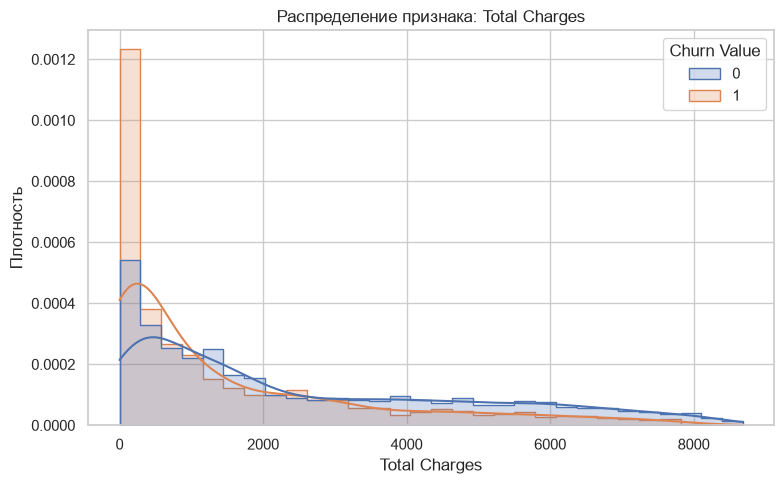

In [89]:
continuous_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
]

for column in continuous_columns:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=column,
        hue=TARGET,
        bins=30,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
    )

    plt.title(f"Распределение признака: {column}")
    plt.xlabel(column)
    plt.ylabel("Плотность")
    plt.tight_layout()

    filename = column.lower().replace(" ", "_")
    plt.savefig(
        FIGURES / f"02_distribution_{filename}.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

- Гистограмма Tenure Months показывает, как распределён срок обслуживания клиентов и отличаются ли по нему ушедшие клиенты от оставшихся.
- Гистограмма Monthly Charges помогает сравнить уровни ежемесячных расходов между классами.
- Гистограмма Total Charges отражает общую сумму начислений, которая зависит в том числе от срока обслуживания.
- Перекрытие распределений означает, что одного признака может быть недостаточно для надёжного определения ухода клиента.

# 7. Сравнение признаков по факту ухода

Сравним количественные признаки для двух групп: клиентов, которые остались, и клиентов, которые ушли.

Boxplot показывает медиану, межквартильный размах и отдельные наблюдения за пределами усов. Такие наблюдения не обязательно являются ошибками: они могут отражать реальные особенности клиентов.

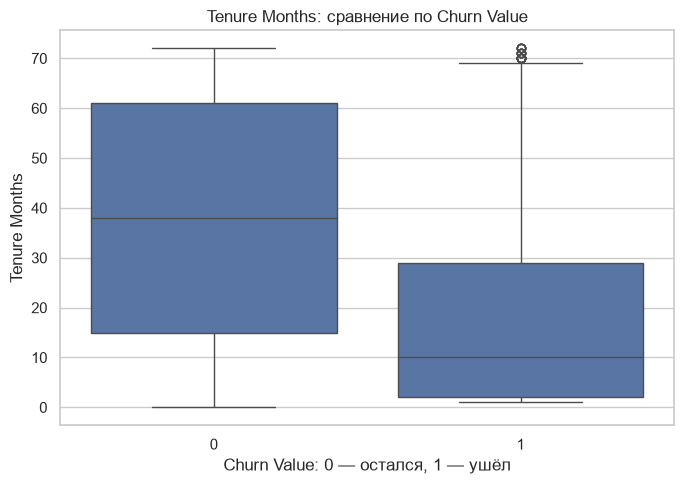

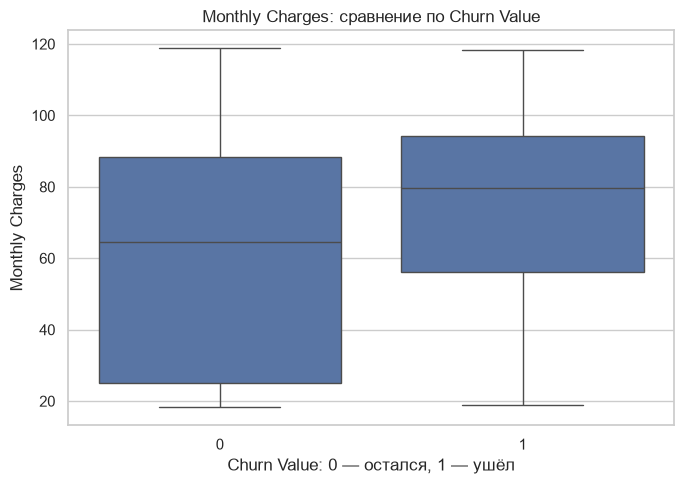

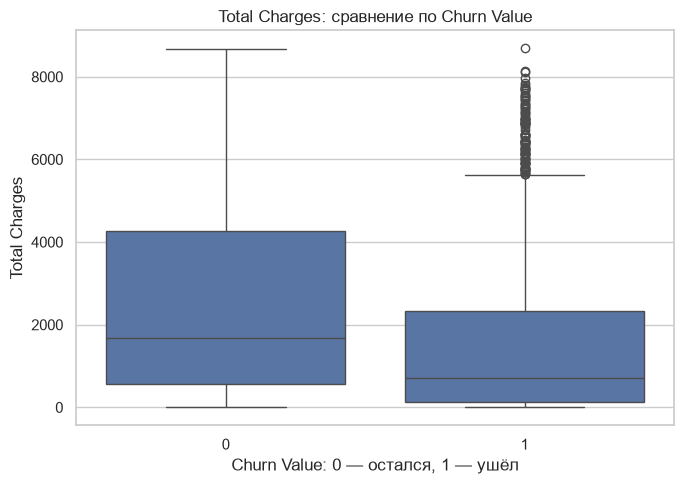

In [90]:
for column in continuous_columns:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=column,
    )

    plt.title(f"{column}: сравнение по Churn Value")
    plt.xlabel("Churn Value: 0 — остался, 1 — ушёл")
    plt.ylabel(column)
    plt.tight_layout()

    filename = column.lower().replace(" ", "_")
    plt.savefig(
        FIGURES / f"03_boxplot_{filename}.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

Сравнение boxplot помогает определить, различаются ли медианы и разброс значений между классами. Эти различия могут быть полезны модели, но сами по себе не доказывают причинно-следственную связь с уходом клиента.

# 8. Анализ категориальных признаков

Рассматриваем распределение клиентов по кодированному типу договора, наличию интернет-услуги и способу оплаты.

Для каждого признака сравним не только количество клиентов, но и долю ушедших внутри каждой группы. Это важно: группа может быть большой по численности, но иметь невысокую долю оттока.


Признак: Contract


,"Ушли, %"
Contract,
0,42.710
1,11.270
2,2.830


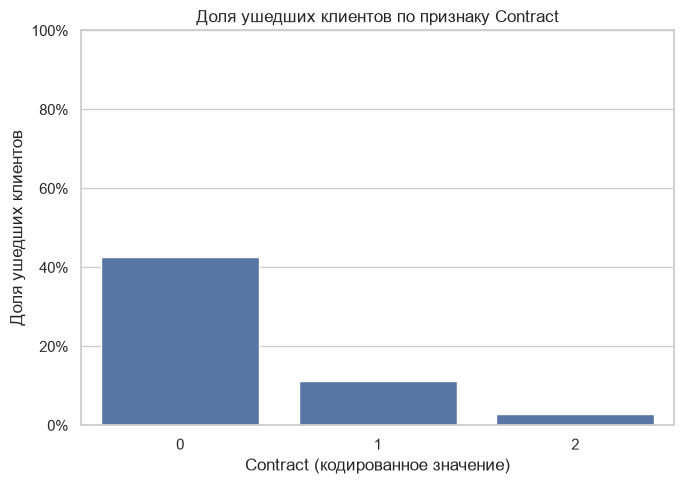


Признак: Internet Service_Fiber optic


,"Ушли, %"
Internet Service_Fiber optic,
0,14.490
1,41.890


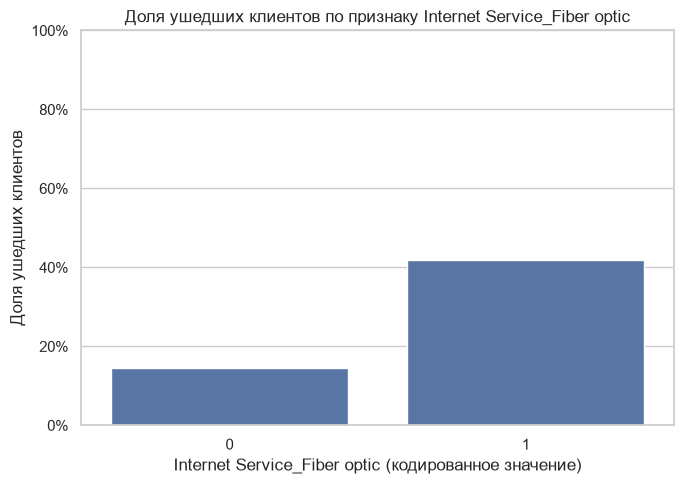


Признак: Internet Service_No


,"Ушли, %"
Internet Service_No,
0,31.830
1,7.400


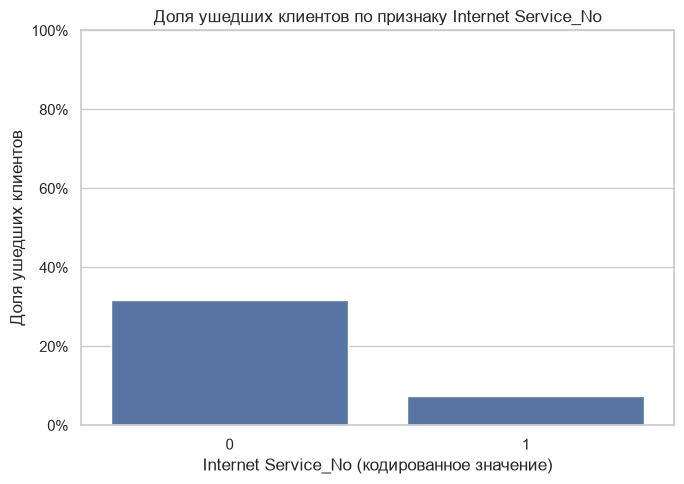


Признак: Payment Method_Credit card (automatic)


,"Ушли, %"
Payment Method_Credit card (automatic),
0,29.650
1,15.240


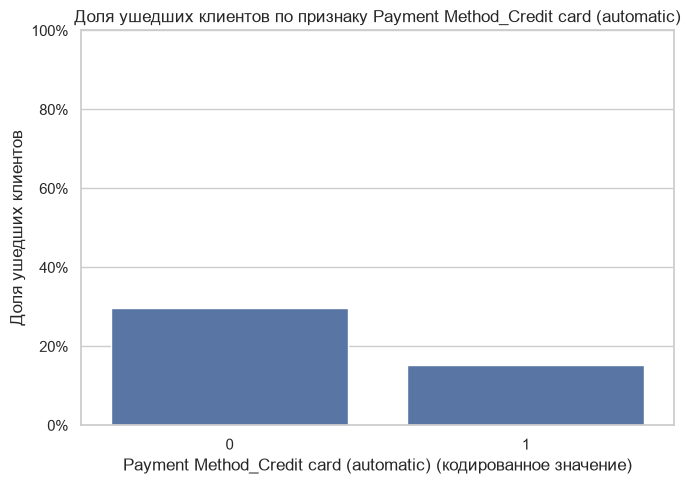


Признак: Payment Method_Electronic check


,"Ушли, %"
Payment Method_Electronic check,
0,17.060
1,45.290


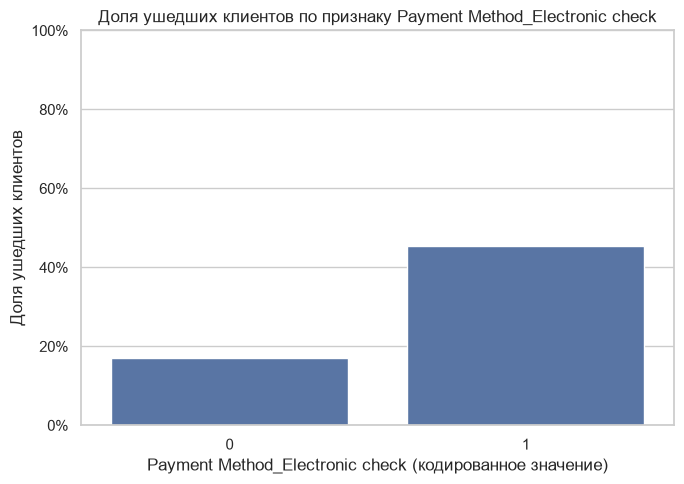


Признак: Payment Method_Mailed check


,"Ушли, %"
Payment Method_Mailed check,
0,28.740
1,19.110


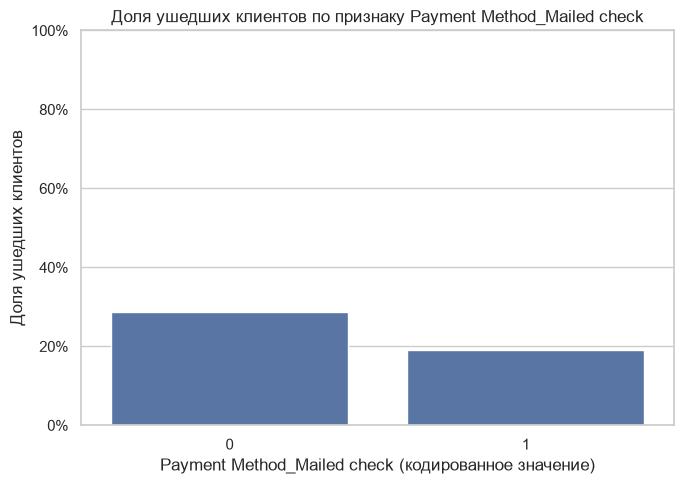

In [91]:
categorical_columns = [
    "Contract",
    "Internet Service_Fiber optic",
    "Internet Service_No",
    "Payment Method_Credit card (automatic)",
    "Payment Method_Electronic check",
    "Payment Method_Mailed check",
]

for column in categorical_columns:
    churn_rate = (
        df.groupby(column, observed=False)[TARGET]
        .mean()
        .mul(100)
        .rename("Ушли, %")
    )

    print(f"\nПризнак: {column}")
    display(churn_rate.round(2).to_frame())

    plt.figure(figsize=(7, 5))

    sns.barplot(
        data=df,
        x=column,
        y=TARGET,
        errorbar=None,
    )

    plt.title(f"Доля ушедших клиентов по признаку {column}")
    plt.xlabel(f"{column} (кодированное значение)")
    plt.ylabel("Доля ушедших клиентов")
    plt.ylim(0, 1)

    # Подписи показывают долю оттока в процентах.
    ax = plt.gca()
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda value, _: f"{value:.0%}")
    )

    plt.tight_layout()

    filename = column.lower().replace(" ", "_").replace("/", "_")
    plt.savefig(
        FIGURES / f"04_churn_rate_{filename}.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

- Графики показывают долю ушедших клиентов внутри каждой категории.
- Для Contract нужно свериться со словарём данных, чтобы установить, какой тип договора обозначает каждый код.
- Для бинарных столбцов 0 означает отсутствие указанной категории, а 1 — её наличие.
- При one-hot-кодировании ноль в одном столбце не обязательно означает отсутствие услуги: клиент может относиться к другой категории.
- Наблюдаемые различия указывают на связь с оттоком, но не доказывают причинность.

# 9. Проверка потенциальных выбросов

Используем межквартильный размах (IQR) для поиска необычно низких или высоких значений.

Проверяем только количественные признаки. Применять этот метод к бинарным столбцам некорректно для поиска реальных выбросов: значения 0 и 1 являются допустимыми категориями.

Найденные значения не удаляются автоматически. Сначала нужно выяснить, являются ли они ошибками или реальными наблюдениями.

In [92]:
Q1 = df[continuous_columns].quantile(0.25)
Q3 = df[continuous_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    df[continuous_columns].lt(lower_bound)
    | df[continuous_columns].gt(upper_bound)
)

outlier_report = pd.DataFrame(
    {
        "Нижняя граница": lower_bound,
        "Верхняя граница": upper_bound,
        "Количество потенциальных выбросов": outlier_mask.sum(),
        "Доля, %": (outlier_mask.sum() / len(df) * 100).round(2),
    }
)

display(outlier_report.round(3))

,Нижняя граница,Верхняя граница,Количество потенциальных выбросов,"Доля, %"
Tenure Months,-60.000,124.000,0,0.000
Monthly Charges,-46.025,171.375,0,0.000
Total Charges,-4683.525,8868.675,0,0.000


IQR выявляет значения, расположенные за пределами статистических границ. Это только сигнал для дополнительной проверки, а не основание для автоматического удаления данных. Например, высокие расходы клиента могут быть реальными.

# 10. Анализ географических координат

Посмотрим, как расположение клиентов связано с целевой переменной. На графике каждая точка соответствует клиенту, а цвет показывает, остался ли клиент с компанией.

Этот график нужен для визуального поиска возможных пространственных закономерностей. Он не доказывает, что географическое положение влияет на отток.

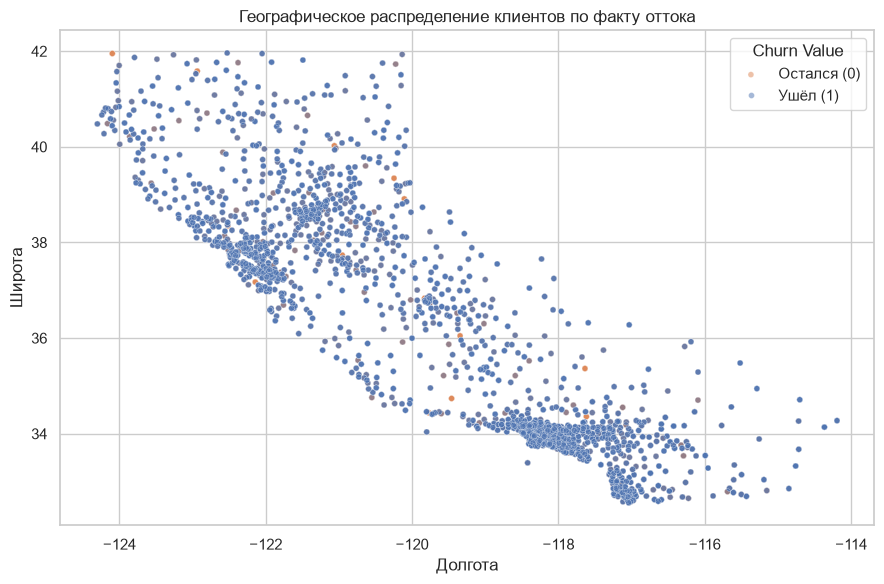

In [93]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Longitude",
    y="Latitude",
    hue=TARGET,
    alpha=0.5,
    s=18,
    palette="deep",
)

plt.title("Географическое распределение клиентов по факту оттока")
plt.xlabel("Долгота")
plt.ylabel("Широта")
plt.legend(title="Churn Value", labels=["Остался (0)", "Ушёл (1)"])
plt.tight_layout()

plt.savefig(
    FIGURES / "05_geographic_churn.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

По графику можно оценить, заметны ли пространственные скопления клиентов и различия между классами. Если точки сильно перекрываются, по этой визуализации нельзя уверенно разделить ушедших и оставшихся клиентов.

# 11. Корреляционный анализ

Рассчитываем корреляцию Пирсона между числовыми признаками и Churn Value.

Корреляция показывает направление и силу линейной связи. Положительное значение означает, что увеличение числового значения признака связано с увеличением Churn Value; отрицательное значение означает обратную связь.

Важно: для бинарных и закодированных категориальных признаков результат требует осторожной интерпретации. Корреляция не доказывает причинно-следственную связь.

Наиболее отрицательные корреляции:


,Корреляция с Churn Value
Contract,-0.397
Tenure Months,-0.352
Dependents,-0.249
Internet Service_No,-0.228
Total Charges,-0.198
Online Security,-0.171
Tech Support,-0.165
Partner,-0.150
Payment Method_Credit card (automatic),-0.134
Payment Method_Mailed check,-0.092



Наиболее положительные корреляции:


,Корреляция с Churn Value
Internet Service_Fiber optic,0.308
Payment Method_Electronic check,0.302
Monthly Charges,0.193
Paperless Billing,0.192
Senior Citizen,0.151
Streaming TV,0.063
Streaming Movies,0.061
Multiple Lines,0.040
Phone Service,0.012
Longitude,0.005


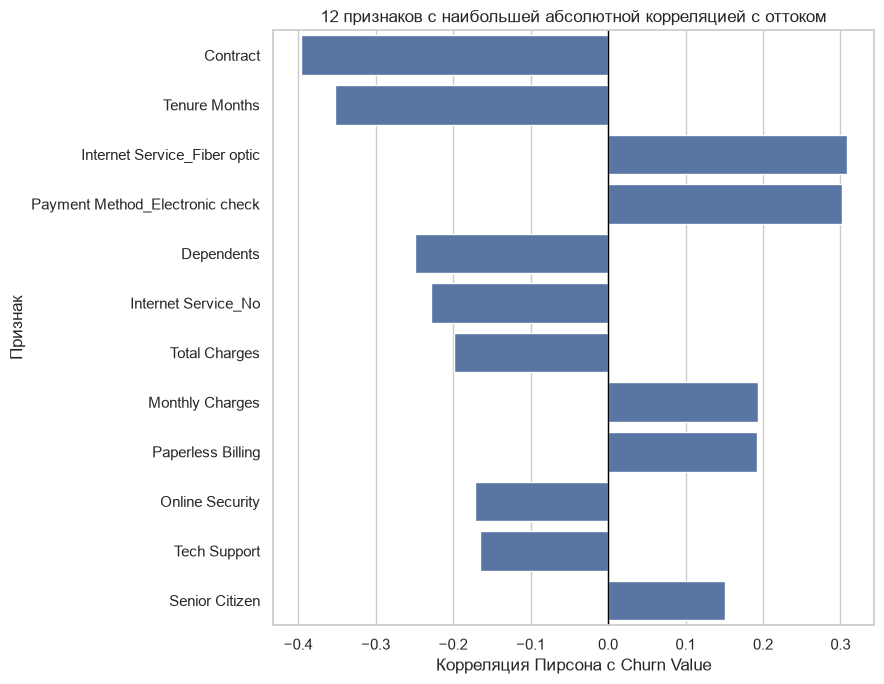

In [94]:
correlations = (
    df.corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values()
)

print("Наиболее отрицательные корреляции:")
display(correlations.head(10).to_frame("Корреляция с Churn Value").round(3))

print("\nНаиболее положительные корреляции:")
display(correlations.tail(10).sort_values(ascending=False).to_frame(
    "Корреляция с Churn Value"
).round(3))

top_correlations = correlations.abs().sort_values(ascending=False).head(12)
top_columns = top_correlations.index

plt.figure(figsize=(9, 7))

sns.barplot(
    x=correlations.loc[top_columns].values,
    y=top_columns,
    errorbar=None,
)

plt.axvline(0, color="black", linewidth=1)
plt.title("12 признаков с наибольшей абсолютной корреляцией с оттоком")
plt.xlabel("Корреляция Пирсона с Churn Value")
plt.ylabel("Признак")
plt.tight_layout()

plt.savefig(
    FIGURES / "06_target_correlations.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

Наиболее заметные связи с Churn Value в этом датасете наблюдаются у Contract, Tenure Months, Payment Method_Electronic check и Internet Service_Fiber optic.

Отрицательная корреляция Contract не означает автоматически, что увеличение кода договора снижает отток: сначала необходимо проверить, как именно закодированы категории. Корреляционный анализ помогает сформировать гипотезы, которые далее можно проверить с помощью модели.

# 12. Подготовка X и y

Для моделирования отделяем целевую переменную от признаков:
- X содержит характеристики клиентов;
- y содержит целевой класс Churn Value.

Перед обучением проверяем типы данных, пропуски и наличие потенциальных признаков утечки. Утечка возникает, когда в признаки попадает информация, которая недоступна на момент реального прогноза или напрямую раскрывает целевое значение.

In [95]:
if TARGET not in df.columns:
    raise ValueError(f"В датасете отсутствует целевая переменная {TARGET!r}")

if df[TARGET].isna().any():
    raise ValueError("В целевой переменной есть пропуски.")

target_values = set(df[TARGET].unique())

if target_values != {0, 1}:
    raise ValueError(
        f"Ожидались классы 0 и 1, получены: {sorted(target_values)}"
    )

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

print(f"Размер X: {X.shape}")
print(f"Размер y: {y.shape}")
print(f"Целевая переменная входит в X: {TARGET in X.columns}")
print(f"Пропусков в X: {X.isna().sum().sum()}")
print(f"Пропусков в y: {y.isna().sum()}")

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
print(f"Нечисловые признаки: {non_numeric}")

print("\nСписок признаков:")
for number, column in enumerate(X.columns, start=1):
    print(f"{number}. {column}")

assert len(X) == len(y)
assert TARGET not in X.columns
assert X.notna().all().all()
assert y.notna().all().all()
assert not non_numeric

Размер X: (7043, 24)
Размер y: (7043,)
Целевая переменная входит в X: False
Пропусков в X: 0
Пропусков в y: 0
Нечисловые признаки: []

Список признаков:
1. Latitude
2. Longitude
3. Gender
4. Senior Citizen
5. Partner
6. Dependents
7. Tenure Months
8. Phone Service
9. Multiple Lines
10. Online Security
11. Online Backup
12. Device Protection
13. Tech Support
14. Streaming TV
15. Streaming Movies
16. Contract
17. Paperless Billing
18. Monthly Charges
19. Total Charges
20. Internet Service_Fiber optic
21. Internet Service_No
22. Payment Method_Credit card (automatic)
23. Payment Method_Electronic check
24. Payment Method_Mailed check


In [96]:
possible_leakage_columns = [
    column
    for column in X.columns
    if any(
        word in column.lower()
        for word in ["churn", "reason", "score", "cltv"]
    )
]

print("Столбцы с названиями, требующими дополнительной проверки:")
print(possible_leakage_columns)

Столбцы с названиями, требующими дополнительной проверки:
[]


Признаки и целевая переменная разделены. Проверка названий столбцов помогает заметить очевидные риски утечки, но не гарантирует её отсутствия: необходимо также проверять смысл признаков и способ их формирования.

# 13. Базовая модель логистической регрессии

Логистическая регрессия — алгоритм классификации, который оценивает вероятность принадлежности объекта к классу 1. В нашем случае это вероятность ухода клиента.

Модель обучается на обучающей выборке, а затем проверяется на тестовой, которая не использовалась при обучении.

Для базового эксперимента используем разделение 80/20 с сохранением пропорций классов (`stratify=y`). Масштабирование и модель объединены в Pipeline: StandardScaler обучается только на обучающей выборке, что помогает избежать утечки информации из тестовых данных.

Этот эксперимент служит базовой точкой сравнения. Если команда уже использует такое же разделение и модель в работе Димы, результаты следует согласовать, а не считать независимым экспериментом.

In [97]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Обучающая выборка: {X_train.shape[0]} объектов")
print(f"Тестовая выборка: {X_test.shape[0]} объектов")

print("\nДоли классов в обучающей выборке:")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nДоли классов в тестовой выборке:")
display((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

Обучающая выборка: 5634 объектов
Тестовая выборка: 1409 объектов

Доли классов в обучающей выборке:


Churn Value
0   73.460
1   26.540
Name: proportion, dtype: float64


Доли классов в тестовой выборке:


Churn Value
0   73.460
1   26.540
Name: proportion, dtype: float64

При стратифицированном разделении доли классов в обучающей и тестовой выборках должны быть близки к долям в исходном датасете. Тестовая выборка остаётся отдельной для итоговой оценки качества модели.

In [98]:
model = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("logistic_regression", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ]
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Модель обучена.")
print(f"Количество признаков: {X_train.shape[1]}")

Модель обучена.
Количество признаков: 24


### Как работает модель

1. `StandardScaler` масштабирует признаки на основе обучающей выборки.
2. `LogisticRegression` находит параметры, позволяющие различать два класса.
3. `predict()` выдаёт класс 0 или 1 при стандартном пороге вероятности 0.5.
4. `predict_proba()` возвращает оценку вероятности каждого класса. Вероятность класса 1 используется для построения ROC-кривой.

Модель выявляет статистические закономерности в данных, но не устанавливает причины ухода клиентов.

# 14. Метрики качества классификации

Оцениваем качество модели на тестовой выборке.

- **Accuracy** — доля правильных прогнозов среди всех объектов.
- **Precision** — какая доля клиентов, которых модель отнесла к ушедшим, действительно ушла.
- **Recall** — какую долю всех ушедших клиентов модель смогла обнаружить.
- **F1-score** — гармоническое среднее Precision и Recall.
- **ROC-AUC** — насколько хорошо модель ранжирует ушедших клиентов выше оставшихся при рассмотрении разных порогов классификации.

При неравномерных классах Accuracy нельзя использовать как единственную метрику.

In [99]:
metrics = pd.DataFrame(
    {
        "Метрика": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score",
            "ROC-AUC",
        ],
        "Значение": [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred, zero_division=0),
            recall_score(y_test, y_pred, zero_division=0),
            f1_score(y_test, y_pred, zero_division=0),
            roc_auc_score(y_test, y_proba),
        ],
    }
)

display(metrics.round(3))

print("Отчёт классификации:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Остался (0)", "Ушёл (1)"],
        zero_division=0,
    )
)

,Метрика,Значение
0,Accuracy,0.801
1,Precision,0.639
2,Recall,0.572
3,F1-score,0.604
4,ROC-AUC,0.848


Отчёт классификации:
              precision    recall  f1-score   support

 Остался (0)       0.85      0.88      0.87      1035
    Ушёл (1)       0.64      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.73      0.74      1409
weighted avg       0.79      0.80      0.80      1409



Метрики показывают разные стороны качества модели. Для задачи обнаружения оттока особенно важно оценивать Recall: низкий Recall означает, что модель пропускает значительную часть ушедших клиентов. При этом увеличение Recall может сопровождаться снижением Precision, поэтому метрики следует рассматривать совместно.

# 15. Матрица ошибок

Матрица ошибок показывает, какие классы модель предсказывает правильно и какие путает.

- True Negative (TN): оставшийся клиент правильно определён как оставшийся.
- False Positive (FP): оставшийся клиент ошибочно определён как ушедший.
- False Negative (FN): ушедший клиент ошибочно определён как оставшийся.
- True Positive (TP): ушедший клиент правильно определён как ушедший.

Для анализа оттока особенно важно смотреть на False Negative: это клиенты, чей уход модель не смогла обнаружить.

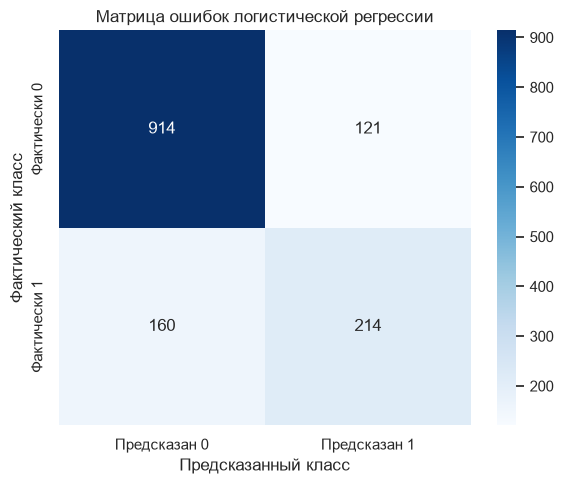

TN — правильно определены оставшиеся: 914
FP — оставшиеся ошибочно определены как ушедшие: 121
FN — ушедшие ошибочно определены как оставшиеся: 160
TP — правильно определены ушедшие: 214


In [100]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Предсказан 0", "Предсказан 1"],
    yticklabels=["Фактически 0", "Фактически 1"],
)

plt.title("Матрица ошибок логистической регрессии")
plt.xlabel("Предсказанный класс")
plt.ylabel("Фактический класс")
plt.tight_layout()

plt.savefig(
    FIGURES / "07_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"TN — правильно определены оставшиеся: {tn}")
print(f"FP — оставшиеся ошибочно определены как ушедшие: {fp}")
print(f"FN — ушедшие ошибочно определены как оставшиеся: {fn}")
print(f"TP — правильно определены ушедшие: {tp}")

Матрица ошибок позволяет увидеть не только общее число ошибок, но и их тип. Для бизнеса цена ложного предупреждения и пропущенного ухода может различаться, поэтому приемлемый порог классификации зависит от цели применения модели.

# 16. ROC-кривая и ROC-AUC

ROC-кривая показывает качество бинарного классификатора при изменении порога, по которому клиент относится к классу 1.

По вертикальной оси находится True Positive Rate (TPR), то есть доля обнаруженных ушедших клиентов. По горизонтальной оси находится False Positive Rate (FPR), то есть доля оставшихся клиентов, ошибочно определённых как ушедшие.

Каждая точка кривой соответствует отдельному порогу классификации.

- Кривая ближе к левому верхнему углу обычно означает лучшее разделение классов.
- Диагональная линия соответствует ориентиру случайного ранжирования.
- ROC-AUC около 0.5 означает качество примерно на уровне случайного ранжирования.
- ROC-AUC ближе к 1 означает более хорошее разделение классов.

ROC-AUC оценивает способность модели ранжировать объекты, а не качество при одном конкретном пороге. Поэтому ROC-AUC нужно рассматривать вместе с Precision, Recall и матрицей ошибок.

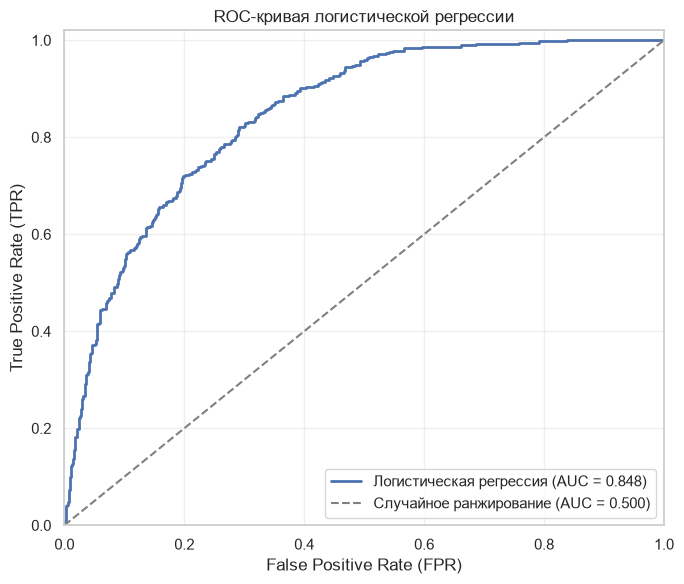

ROC-AUC на тестовой выборке: 0.848


In [101]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Логистическая регрессия (AUC = {roc_auc:.3f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Случайное ранжирование (AUC = 0.500)",
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC-кривая логистической регрессии")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES / "08_roc_curve.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(f"ROC-AUC на тестовой выборке: {roc_auc:.3f}")

In [102]:
if roc_auc < 0.6:
    roc_interpretation = "разделение классов слабое"
elif roc_auc < 0.7:
    roc_interpretation = "разделение классов невысокое"
elif roc_auc < 0.8:
    roc_interpretation = "разделение классов умеренное"
elif roc_auc < 0.9:
    roc_interpretation = "разделение классов хорошее"
else:
    roc_interpretation = "разделение классов очень хорошее"

print(f"ROC-AUC = {roc_auc:.3f}: {roc_interpretation}.")
print(
    "Это оценка на одной тестовой выборке; "
    "для сравнения методов нужно использовать одинаковые условия эксперимента."
)

ROC-AUC = 0.848: разделение классов хорошее.
Это оценка на одной тестовой выборке; для сравнения методов нужно использовать одинаковые условия эксперимента.


# 17. Коэффициенты логистической регрессии

Посмотрим на признаки, которым модель присвоила наибольшие по абсолютной величине коэффициенты.

Поскольку перед обучением использовался StandardScaler, коэффициенты относятся к масштабированным признакам. Положительный коэффициент связан с увеличением прогнозируемой вероятности ухода, отрицательный — с её уменьшением при прочих равных условиях.

Это не причинно-следственные эффекты. При наличии взаимосвязанных признаков коэффициенты могут зависеть друг от друга.

,Коэффициент
Internet Service_Fiber optic,0.664
Total Charges,0.518
Streaming TV,0.230
Streaming Movies,0.215
Multiple Lines,0.209
Payment Method_Electronic check,0.178
Paperless Billing,0.177
Internet Service_No,-0.552
Contract,-0.577
Dependents,-0.687


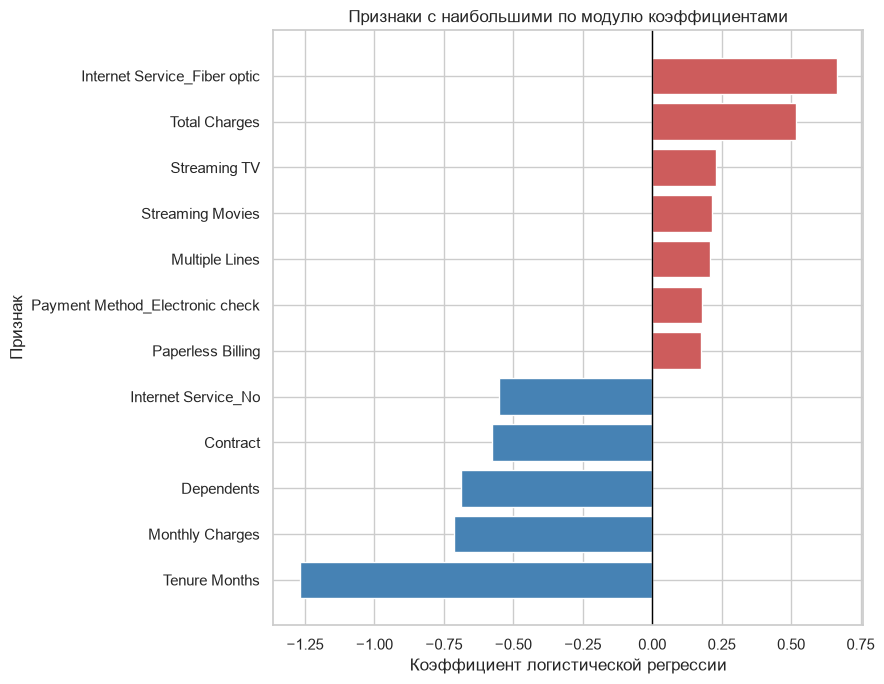

In [103]:
coefficients = pd.Series(
    model.named_steps["logistic_regression"].coef_[0],
    index=X.columns,
    name="Коэффициент",
)

top_coefficients = (
    coefficients
    .loc[coefficients.abs().nlargest(12).index]
    .sort_values()
)

display(
    top_coefficients.to_frame()
    .sort_values("Коэффициент", ascending=False)
    .round(3)
)

plt.figure(figsize=(9, 7))

colors = [
    "steelblue" if value < 0 else "indianred"
    for value in top_coefficients.values
]

plt.barh(
    top_coefficients.index,
    top_coefficients.values,
    color=colors,
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Признаки с наибольшими по модулю коэффициентами")
plt.xlabel("Коэффициент логистической регрессии")
plt.ylabel("Признак")
plt.tight_layout()

plt.savefig(
    FIGURES / "09_logistic_coefficients.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

График показывает направление и относительную величину коэффициентов базовой модели. Положительные коэффициенты связаны с более высокой оценкой вероятности ухода, отрицательные — с более низкой. Для закодированных категорий интерпретация зависит от схемы кодирования.

# 18. Итоговые выводы

В ходе анализа были проверены структура и качество данных, распределение целевой переменной, количественные и категориальные признаки, потенциальные выбросы и корреляции.

Затем была построена базовая логистическая регрессия. Качество оценивалось на отдельной тестовой выборке с помощью Accuracy, Precision, Recall, F1-score, ROC-AUC и матрицы ошибок.

Результаты базовой модели позволяют получить отправную точку для дальнейшего сравнения методов разделения данных и моделей классификации. Выводы о практической полезности модели следует делать по совокупности метрик, а не по одному показателю.

In [104]:
print("ИТОГОВАЯ СВОДКА")
print("-" * 50)

print(f"Наблюдений: {len(df)}")
print(f"Признаков без целевой переменной: {X.shape[1]}")
print(f"Доля ушедших клиентов: {y.mean() * 100:.2f}%")
print(f"Пропусков в исходном датасете: {df.isna().sum().sum()}")
print(f"Полных дубликатов: {df.duplicated().sum()}")

print("\nКачество базовой логистической регрессии:")
for _, row in metrics.iterrows():
    print(f"{row['Метрика']}: {row['Значение']:.3f}")

print("\nГлавные замечания:")
print("1. Классы целевой переменной распределены неравномерно.")
print("2. Корреляция не доказывает причинно-следственную связь.")
print("3. Потенциальные выбросы нельзя удалять без дополнительной проверки.")
print("4. ROC-AUC нужно оценивать вместе с Precision, Recall и F1-score.")
print("5. Для сравнения моделей необходимо соблюдать одинаковые условия эксперимента.")

ИТОГОВАЯ СВОДКА
--------------------------------------------------
Наблюдений: 7043
Признаков без целевой переменной: 24
Доля ушедших клиентов: 26.54%
Пропусков в исходном датасете: 0
Полных дубликатов: 0

Качество базовой логистической регрессии:
Accuracy: 0.801
Precision: 0.639
Recall: 0.572
F1-score: 0.604
ROC-AUC: 0.848

Главные замечания:
1. Классы целевой переменной распределены неравномерно.
2. Корреляция не доказывает причинно-следственную связь.
3. Потенциальные выбросы нельзя удалять без дополнительной проверки.
4. ROC-AUC нужно оценивать вместе с Precision, Recall и F1-score.
5. Для сравнения моделей необходимо соблюдать одинаковые условия эксперимента.
